In [1]:
import numpy as np
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
np.random.seed(28)
X,y = make_circles(n_samples=500,factor=0.1, noise=0.30, random_state=28)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=28)

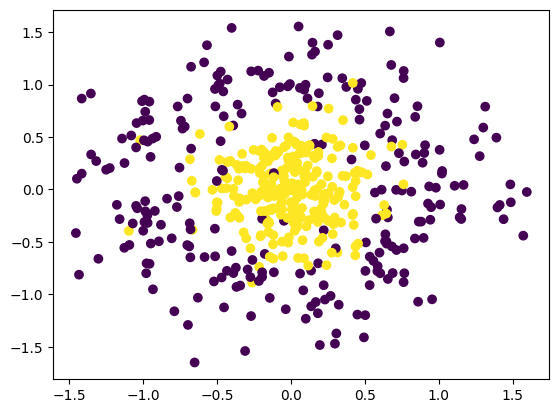

In [3]:
plt.scatter(X[:,0],X[:,1],c=y)

In [5]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(random_state=28)

In [6]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=28)

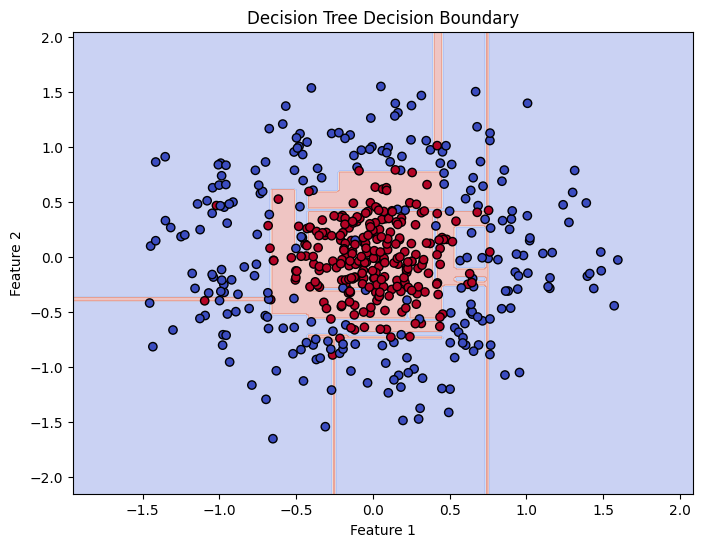

In [7]:
# Plotting decision boundary for DecisionTreeClassifier
import numpy as np

# Create a mesh grid
h = 0.02
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Predict on mesh grid
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=plt.cm.coolwarm)
plt.title("Decision Tree Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [8]:
from sklearn.ensemble import RandomForestClassifier

In [9]:
clf1 = RandomForestClassifier(n_estimators=500, random_state=28)

In [10]:
clf1.fit(X_train,y_train)

RandomForestClassifier(n_estimators=500, random_state=28)

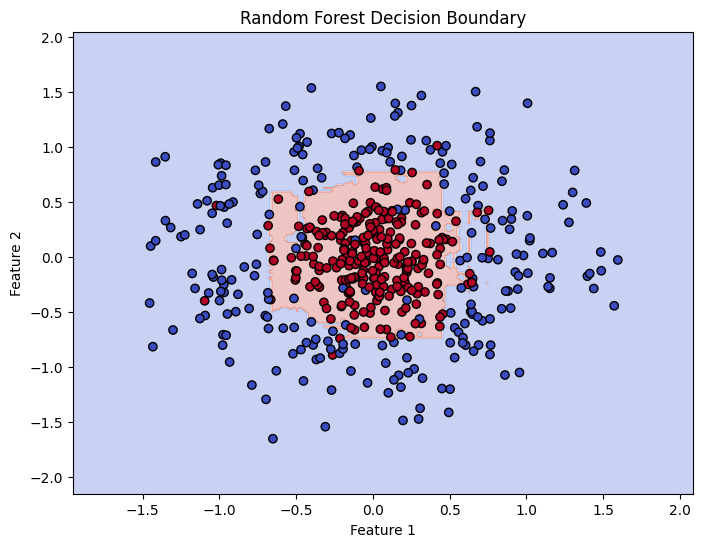

In [11]:
# Plotting decision boundary for RandomForestClassifier
h = 0.02
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Z = clf1.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=plt.cm.coolwarm)
plt.title("Random Forest Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [19]:
n_train = 150
n_test = 1000
noise = 0.1

def f(x):
    x = x.ravel()
    return np.exp(-x**2) + 1.5 * np.exp(-(x - 2)** 2)

def generate(n_samples, noise):
    X = np.random.rand(n_samples) * 10 - 5
    X = np.sort(X).ravel()
    y = np.exp(-X**2) + 1.5 * np.exp(-(X - 2)** 2)\
        + np.random.normal(0.0, noise, n_samples)
    X = X.reshape((n_samples,1))

    return X,y

In [20]:
X_train , y_train = generate(n_train,noise)
X_test, y_test = generate(n_test,noise)

(-5.0, 5.0)

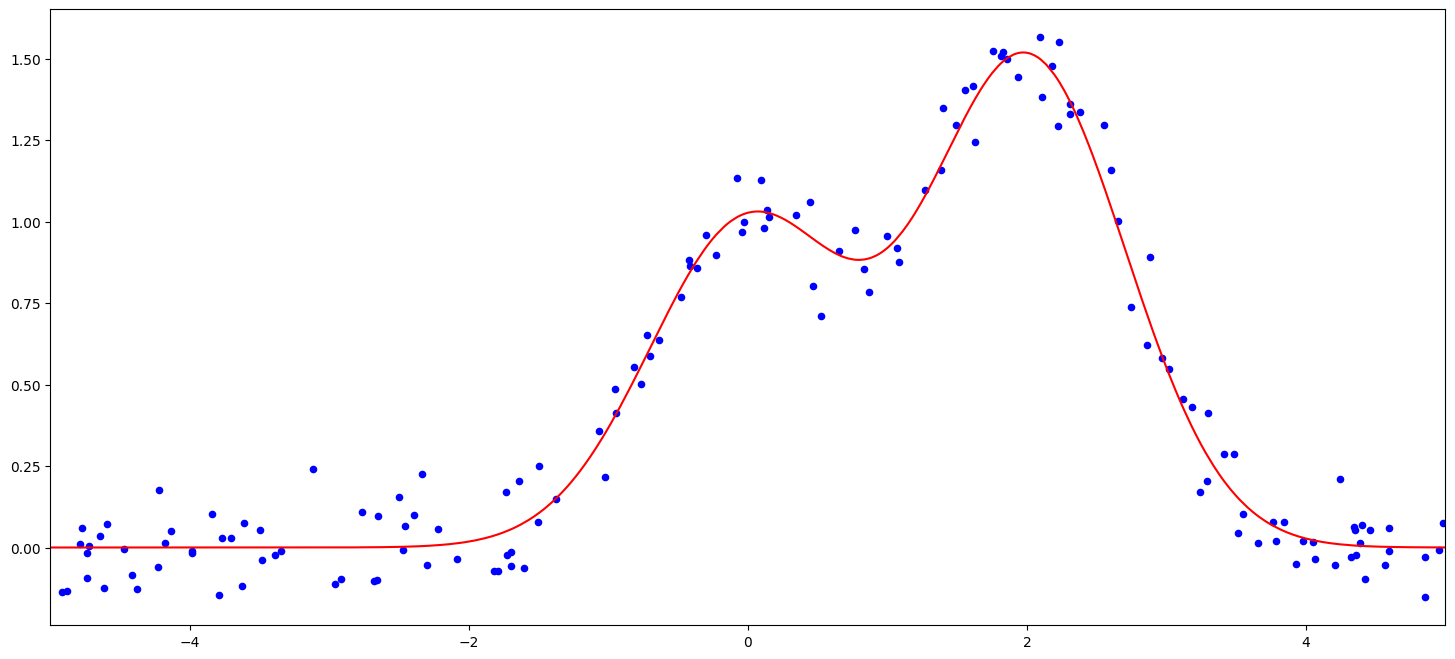

In [21]:
plt.figure(figsize=(18,8))
plt.plot(X_test, f(X_test),'r')
plt.scatter(X_train, y_train, c='b', s=20)
plt.xlim([-5,5])

In [23]:
from sklearn.tree import DecisionTreeRegressor
clf3 = DecisionTreeRegressor()
clf3.fit(X_train, y_train)
d_pred = clf3.predict(X_test)

(-5.0, 5.0)

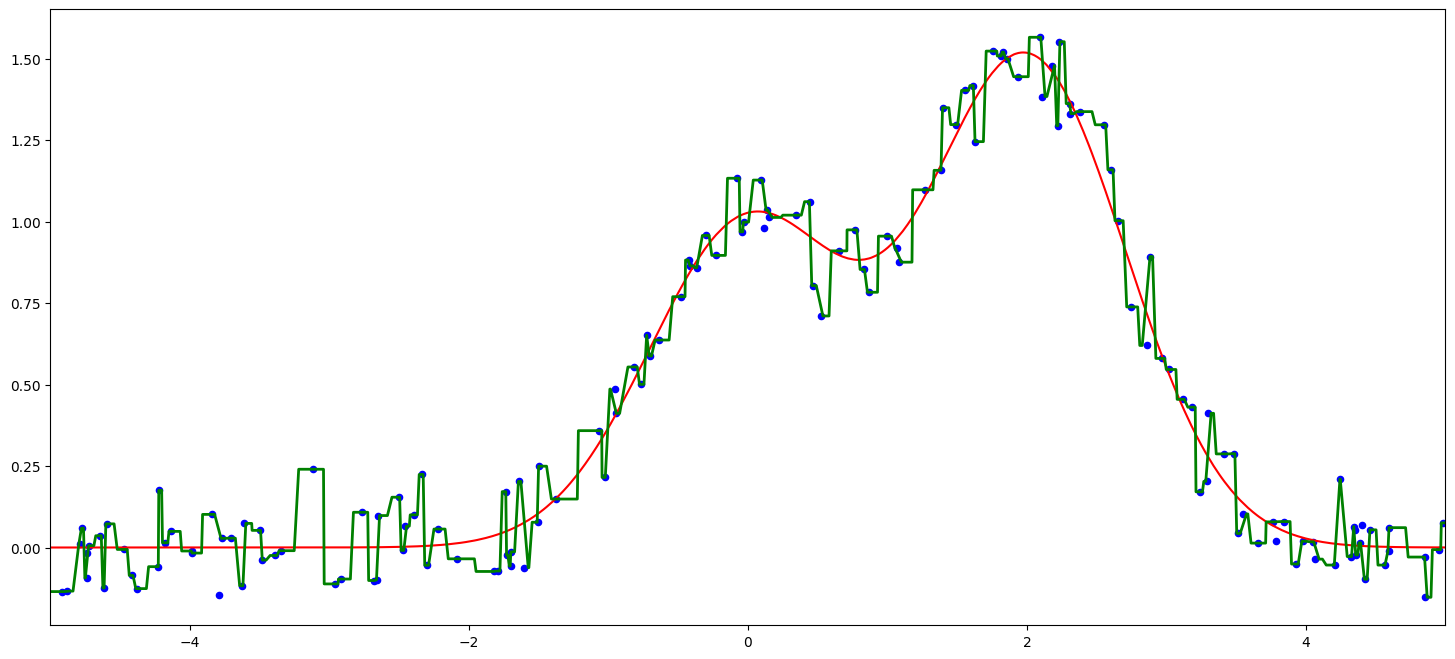

In [24]:
plt.figure(figsize=(18,8))
plt.plot(X_test, f(X_test),'r')
plt.scatter(X_train, y_train, c='b', s=20)
plt.plot(X_test, d_pred, 'g', lw=2)
plt.xlim([-5,5])

In [30]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=10000, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

(-5.0, 5.0)

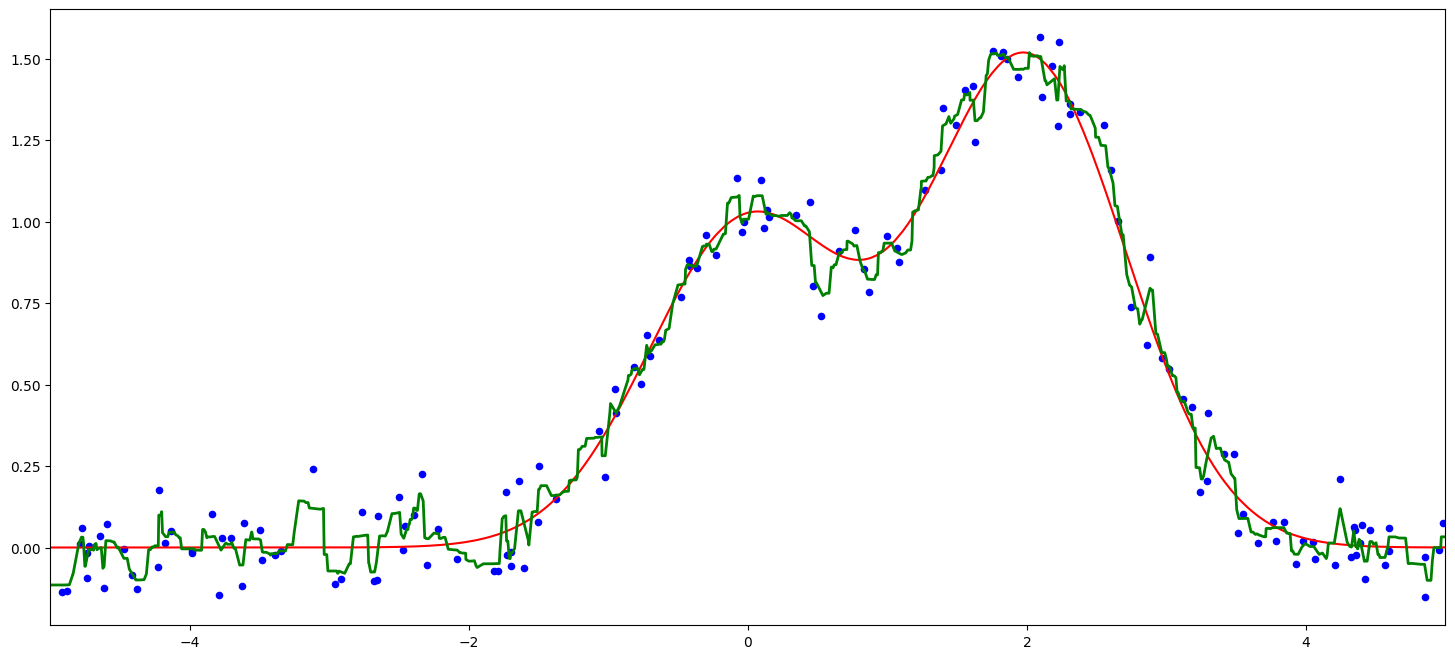

In [29]:
plt.figure(figsize=(18,8))
plt.plot(X_test, f(X_test),'r')
plt.scatter(X_train, y_train, c='b', s=20)
plt.plot(X_test, y_pred, 'g', lw=2)
plt.xlim([-5,5])